In [33]:
%load_ext autoreload
%autoreload 2

from IPython.display import display
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

import main_analysis as ma

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'Avenir'

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/postvss25'
os.makedirs(PLOTS_DIR, exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [34]:
tthreshold = 7
randommodel_tthreshold = 3
frois = ['FFA', 'PPA', 'EBA']
model_localizers = ['grillspector', 'kanwisher', 'nsd']

SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_nsd515.csv'

all_task_optimized_model_names = ma.get_model_names(model_type='task_optimized')
all_random_model_names = ma.get_model_names(model_type='random')

savefig = False

plot_dir = f'{PLOTS_DIR}/fig3/boxplots'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

# Final: Repeating units per voxel


normed_pearsonr
FFA
PPA
EBA

normed_rdmr
FFA
PPA
EBA


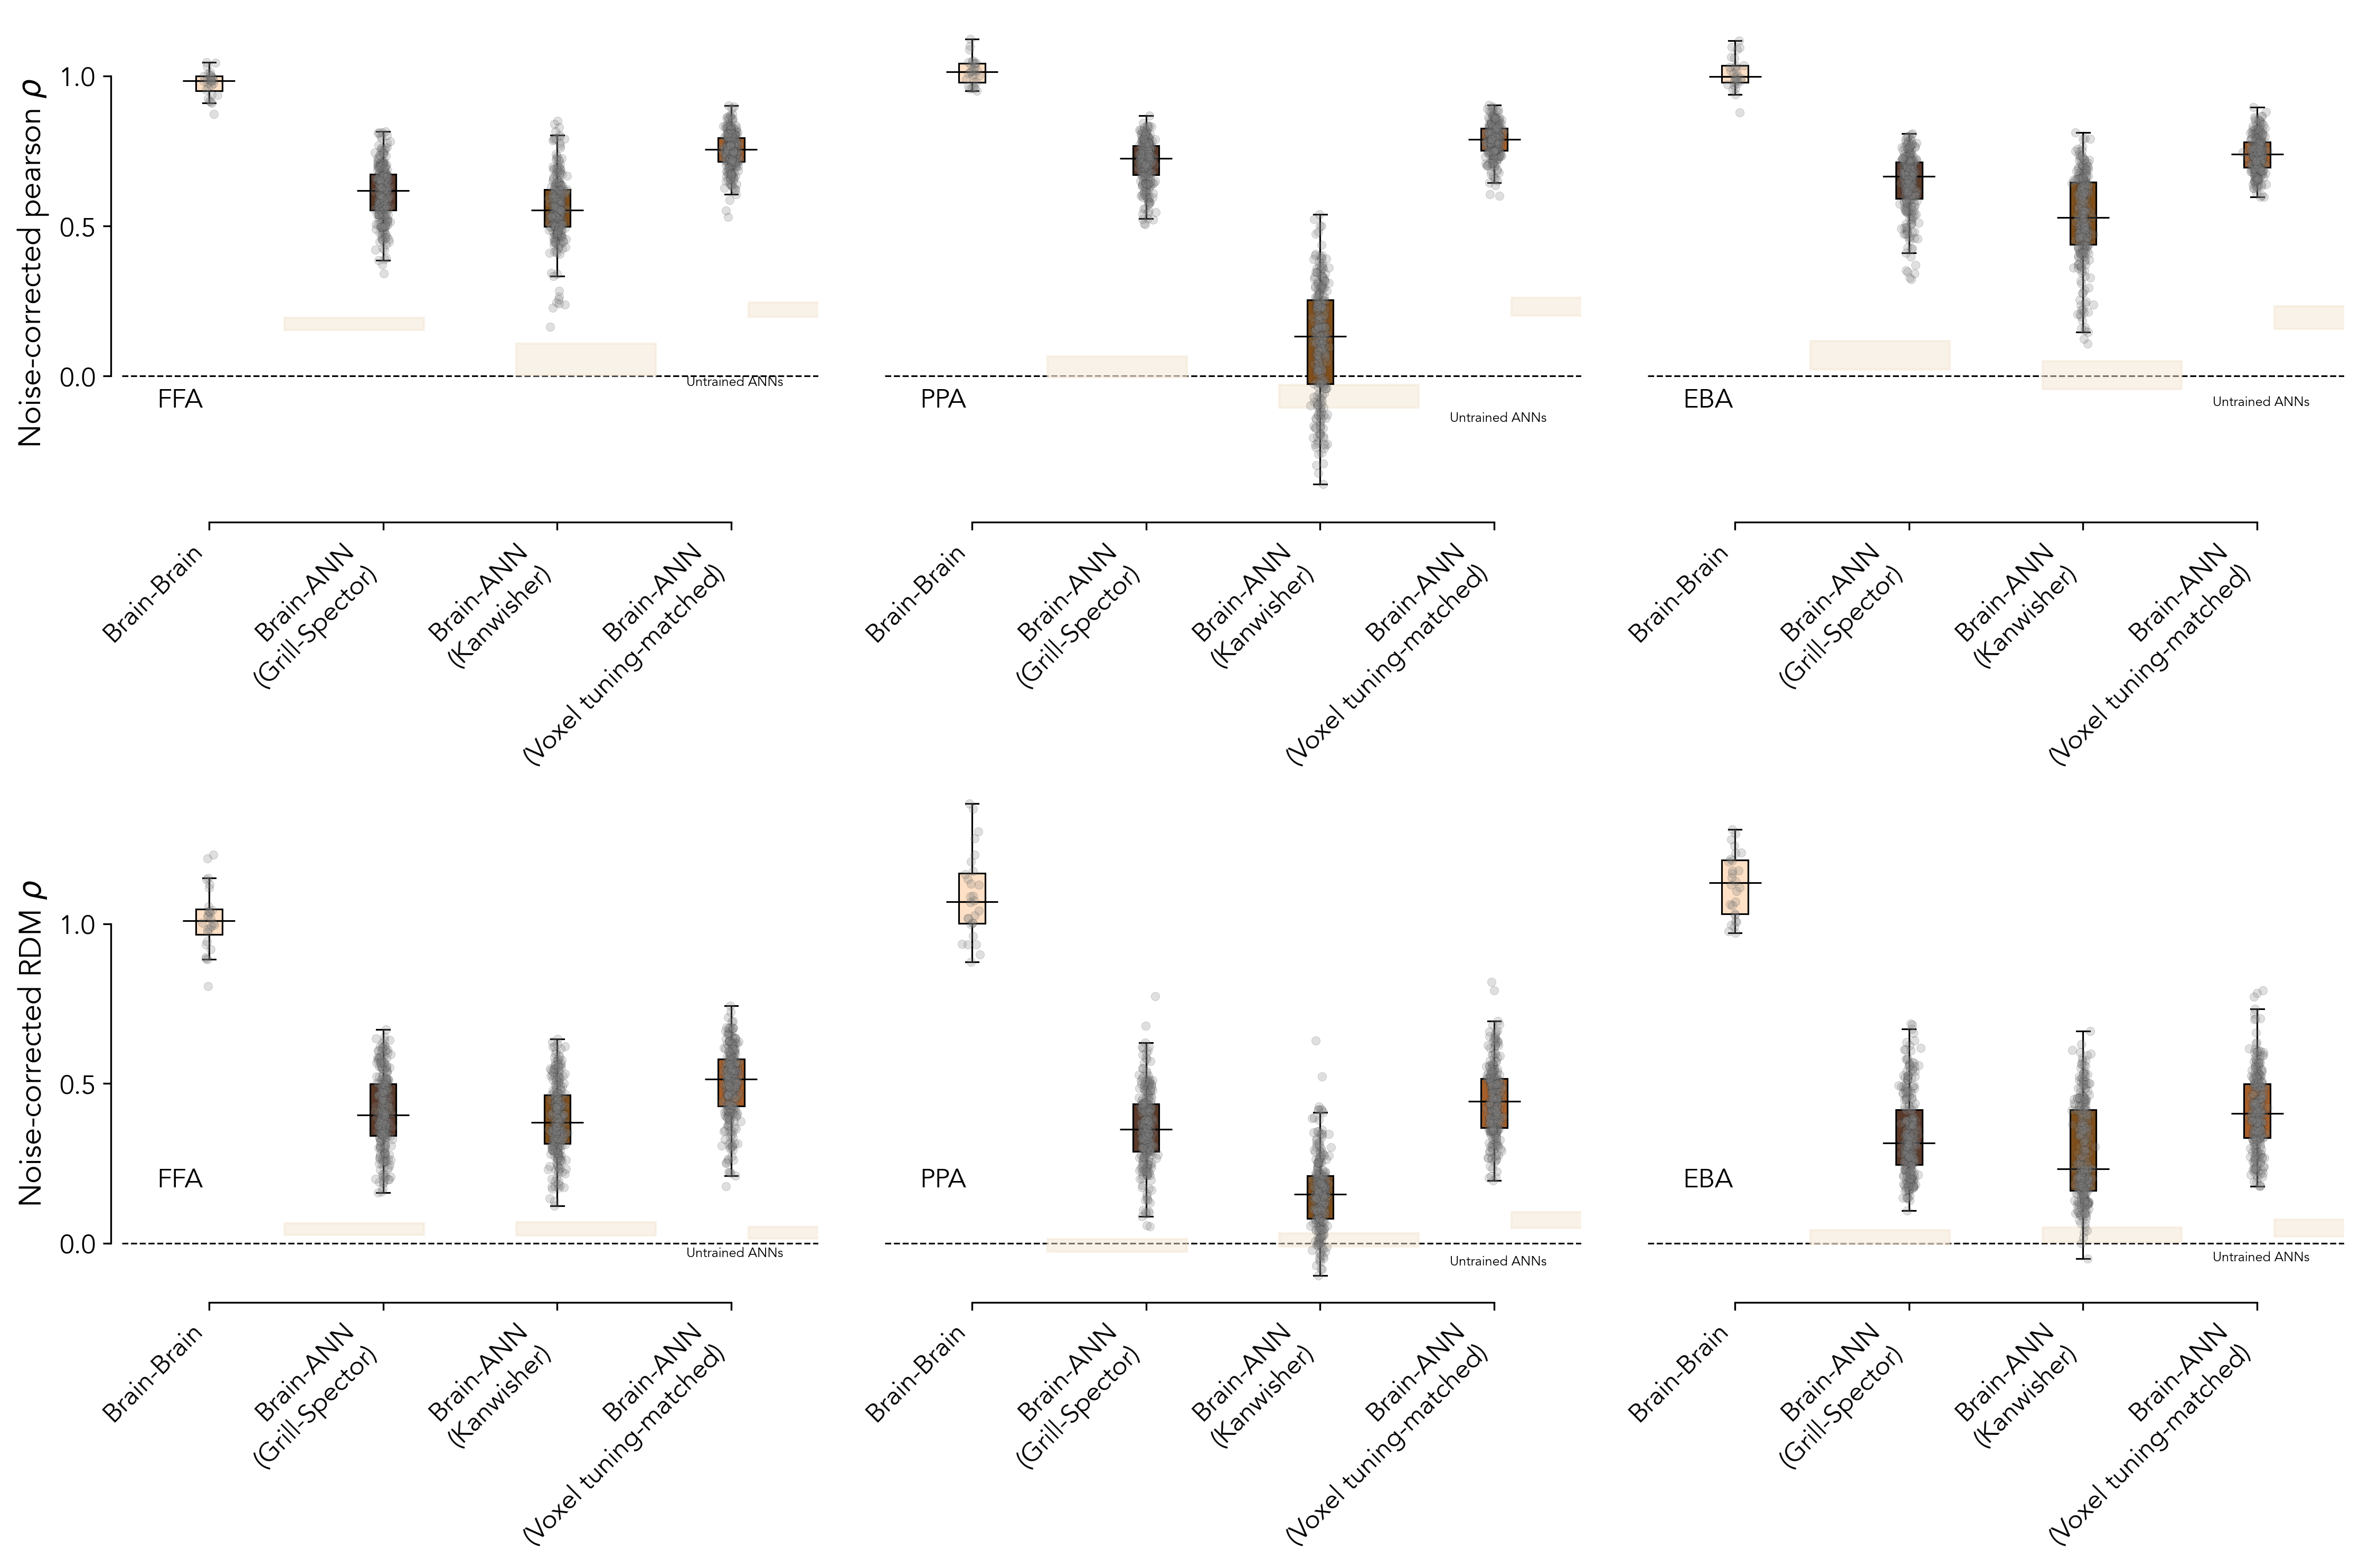

In [ ]:
tthreshold = 7
randommodel_tthreshold = 3
frois = ['FFA', 'PPA', 'EBA']
model_localizers = ['grillspector', 'kanwisher', 'nsd']

SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_nsd515.csv'

all_task_optimized_model_names = ma.get_model_names(model_type='task_optimized')
all_random_model_names = ma.get_model_names(model_type='random')

savefig = False

plot_dir = f'{PLOTS_DIR}/fig3/boxplots'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
subjects = subjectsubject_correlations_csv['subject1'].unique()
models = modelsubject_correlations_csv['model_name'].unique()

taskoptimized_models = [model for model in models if model in all_task_optimized_model_names]
# Random models
random_models = [model for model in models if model in all_random_model_names]

hh_color = '#fde0c5' # Light peach
random_color = '#f5e6d3' # Very light brown

localizer_color_dict = {
    'grillspector': '#5c3a29',  # Dark Brown
    'kanwisher': '#7f4e1a',     # A Shade lighter than dark brown
    'nsd': '#a65f2a'            # A shade lighter than that
}
localizer_name_dict = {
    'grillspector': 'Grill-Spector',
    'kanwisher': 'Kanwisher',
    'nsd': 'Voxel tuning-matched'
}

metrics = ['normed_pearsonr', 'normed_rdmr']
lims_dict = {
    'normed_pearsonr': (-0.45, 1.2),
    'normed_rdmr': (-0.15, 1.4)
}
ticks_dict = {
    'normed_pearsonr': [0, 0.5, 1],
    'normed_rdmr': [0, 0.5, 1]
}

# fig, ax = plt.figure(figsize=(5, 5), dpi=300)
fig, axes = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

for midx, metric in enumerate(metrics):
    print()
    print(metric)
    for fidx, froi in enumerate(frois):
        ax = axes[midx, fidx]
        print(froi)
        hh_medians = []
        for subject in subjects:
            subjectsubject_froi = subjectsubject_correlations_csv[
                (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                (subjectsubject_correlations_csv['subject1'] == subject) &
                (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
            ]
            hh_medians += list(subjectsubject_froi[metric])
        hh_medians = np.array(hh_medians).flatten()

        # Model correlations
        model_corrs = {}
        for model_localizer in model_localizers:
            model_corrs[model_localizer] = {}
            # Get random model correlations
            random_medians = []
            for model in random_models:
                modelsubject_froi = modelsubject_correlations_csv[
                    (modelsubject_correlations_csv['fmri_froi'] == froi) &
                    (modelsubject_correlations_csv['model_name'] == model) &
                    (modelsubject_correlations_csv['fmri_tthreshold'] == randommodel_tthreshold) &
                    (modelsubject_correlations_csv['model_tthreshold'] == randommodel_tthreshold) &
                    (modelsubject_correlations_csv['model_localizer'] == model_localizer)
                ]
                # Take median across subjects for this model
                random_medians += list(modelsubject_froi[metric])
            random_medians = np.array(random_medians)
            model_corrs[model_localizer]['random'] = random_medians

            # Separate task-optimized and brain-optimized models
            to_medians = []
            for model in taskoptimized_models:
                modelsubject_froi = modelsubject_correlations_csv[
                    (modelsubject_correlations_csv['fmri_froi'] == froi) &
                    (modelsubject_correlations_csv['model_name'] == model) &
                    (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
                    (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
                    (modelsubject_correlations_csv['model_localizer'] == model_localizer)
                ]
                model_medians = list(modelsubject_froi[metric])
                # Mann-Whitney U test for each model vs. hh_medians
                ustat, pval = scipy.stats.mannwhitneyu(model_medians, hh_medians, alternative='less')
                if pval >= 0.05:
                    print(f"Model {model} ({model_localizer}) is plausibly within the human population (p={pval:.2e})")
                to_medians += model_medians
            model_corrs[model_localizer]['task_optimized'] = np.array(to_medians)

        jitter_scale = 0.01 #0.05
        scatter_pad = 0 # 0.05
        alpha = 0.25 # 0.5
        markersize = 15 # 25

        bar_positions = np.array([0, 0.5, 1.0, 1.5])

        # y=0 line
        ax.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

        # Shaded region for random model correlations
        # if len(random_medians) > 0:
        #     random_q1 = np.percentile(random_medians, 25)
        #     random_q3 = np.percentile(random_medians, 75)
        #     ax.axhspan(random_q1, random_q3, color=random_color, alpha=0.5, zorder=1)
        #     # Add text annotation for Random Models
        #     random_median = np.median(random_medians)
        #     ax.text(0.35, random_median, 'Untrained ANNs', fontsize=10, va='center', ha='right', 
        #             transform=ax.get_yaxis_transform())
        for i, model_localizer in enumerate(model_localizers):
            i = i + 1  # Shift by 1 since 0 is hh
            random_medians = model_corrs[model_localizer]['random']
            random_q1 = np.percentile(random_medians, 25)
            random_q3 = np.percentile(random_medians, 75)
            # Keep shifting the shaded region to the right for each localizer
            ax.axhspan(random_q1, random_q3, color=random_color, alpha=0.5, zorder=1,
                       xmin=(bar_positions[i] - 0.15)/(bar_positions[-1]+0.25),
                       xmax=(bar_positions[i] + 0.15)/(bar_positions[-1]+0.25))
            if i == len(model_localizers) - 1:
                # Add text annotation for Random Models
                random_median = np.median(random_medians)
                ax.text(bar_positions[-2]-0.05, random_median-0.075, f'Untrained ANNs', fontsize=6, va='center', ha='right', 
                        transform=ax.get_yaxis_transform())

        # Box plot for brain-brain, and brain-ann for each model localizer
        box_data = [hh_medians]
        for model_localizer in model_localizers:
            box_data.append(model_corrs[model_localizer]['task_optimized'])
        linewidth = 0.75
        barwidth = 0.075 # 0.35
        medianlineextra = 0.075
        boxes = ax.boxplot(
                    box_data, positions=bar_positions, patch_artist=True, 
                    widths=barwidth, showfliers=False,
                    boxprops={'color': 'black', 'linewidth': linewidth},
                    whiskerprops=dict(linewidth=linewidth),
                    capprops=dict(linewidth=linewidth),
                    medianprops={'color': 'black', 'linewidth': linewidth},
                    flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
                )
        for i, data in enumerate(box_data):
            med = np.median(data)
            # Manually draw a longer median line
            x = bar_positions[i]  # X-position of the boxplot
            # 0.225
            ax.plot([x - medianlineextra, x + medianlineextra], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
        
        # Color the boxes according to category colors
        colors = [hh_color] + [localizer_color_dict[model_localizer] for model_localizer in model_localizers]
        for box, color in zip(boxes['boxes'], colors):
            box.set(facecolor=color)
        
        # Scatter individual data points
        for i, data in enumerate(box_data):
            x_ = np.zeros(len(data)) + bar_positions[i] + np.random.normal(0, jitter_scale, len(data))
            x_ += scatter_pad
            ax.scatter(
                x_, data, color='gray', alpha=alpha, zorder=5,
                edgecolors=(0, 0, 0), s=markersize, linewidths=0.15
            )
            # print(f'Bar position {bar_positions[i]}: n={len(data)}')
        
        # Write froi name in bottom left corner
        ax.text(0.05, 0.25, froi, transform=ax.transAxes, fontsize=12, verticalalignment='top')

        yticks = np.array(ticks_dict[metric])
        ylims = lims_dict[metric]
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.set_yticks(yticks)
        ax.set_yticklabels(yticks, fontsize=12)
        ax.spines['left'].set_bounds(yticks.min(), yticks.max())
        # plt.tick_params(axis='y', labelleft=False)
        ax.set_ylim(ylims)
        ax.spines['bottom'].set_bounds(bar_positions[0], bar_positions[-1])
        ax.set_xlim(bar_positions[0]-0.25, bar_positions[-1]+0.25)
        # ax.tick_params(axis='x', labelbottom=False)

        if fidx != 0:
            ax.spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            ax.yaxis.set_ticks([])
        else:
            if metric == 'normed_pearsonr':
                ax.set_ylabel(r'Noise-corrected pearson $\rho$', fontsize=14)
            else:
                ax.set_ylabel(r'Noise-corrected RDM $\rho$', fontsize=14)
        # x-label on all plots for now
        # ax.set_xticks(bar_positions, ['Brain-Brain', 'Brain-ANN\n(Task-Optimized)', 'Brain-ANN\n(Brain-Optimized)'], fontsize=12)
        xtick_labels = ['Brain-Brain'] + \
            [f'Brain-ANN\n({localizer_name_dict[model_localizer]})' for model_localizer in model_localizers]
        ax.set_xticks(bar_positions)
        ax.set_xticklabels(xtick_labels, fontsize=12, rotation=45, ha='right')

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/fig3_sup_otherfrois.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()


# Extra sanity check: Unique units per voxel within-subject


normed_pearsonr
FFA
Human median: 0.9862885991540676
PPA
Human median: 1.018733818538227
EBA
Human median: 1.0272396498385603

normed_rdmr
FFA
Human median: 1.0348288710119955
nsd; alexnetimagenet1kv1 median: 0.5703077801522478
nsd; alexnetipclref01 median: 0.35780446203327815
nsd; alexnetbarlowtwins median: 0.36583167569488784
nsd; vgg16imagenet1kv1 median: 0.5343388717435935
nsd; resnet18imagenet1kv1 median: 0.3950597027651334
nsd; resnet50imagenet1kv2 median: 0.5961210826499443
nsd; resnet50openaiclip median: 0.6218150568417373
nsd; resnet50simclr median: 0.6409815258313406
nsd; resnet50robustl2eps3 median: 0.5220572597848295
nsd; resnet50sin median: 0.5505967317023069
nsd; resnet50ecoset median: 0.5285143855649697
nsd; resnet50faceobfuscation median: 0.5735663547827691
nsd; resnet50toponettau30 median: 0.6146085990709818
nsd; resnet101imagenet1kv1 median: 0.601405682236408
nsd; resnet101openaiclip median: 0.5873526056207825
nsd; bagnet33 median: 0.5611077888829901
nsd; cornets med

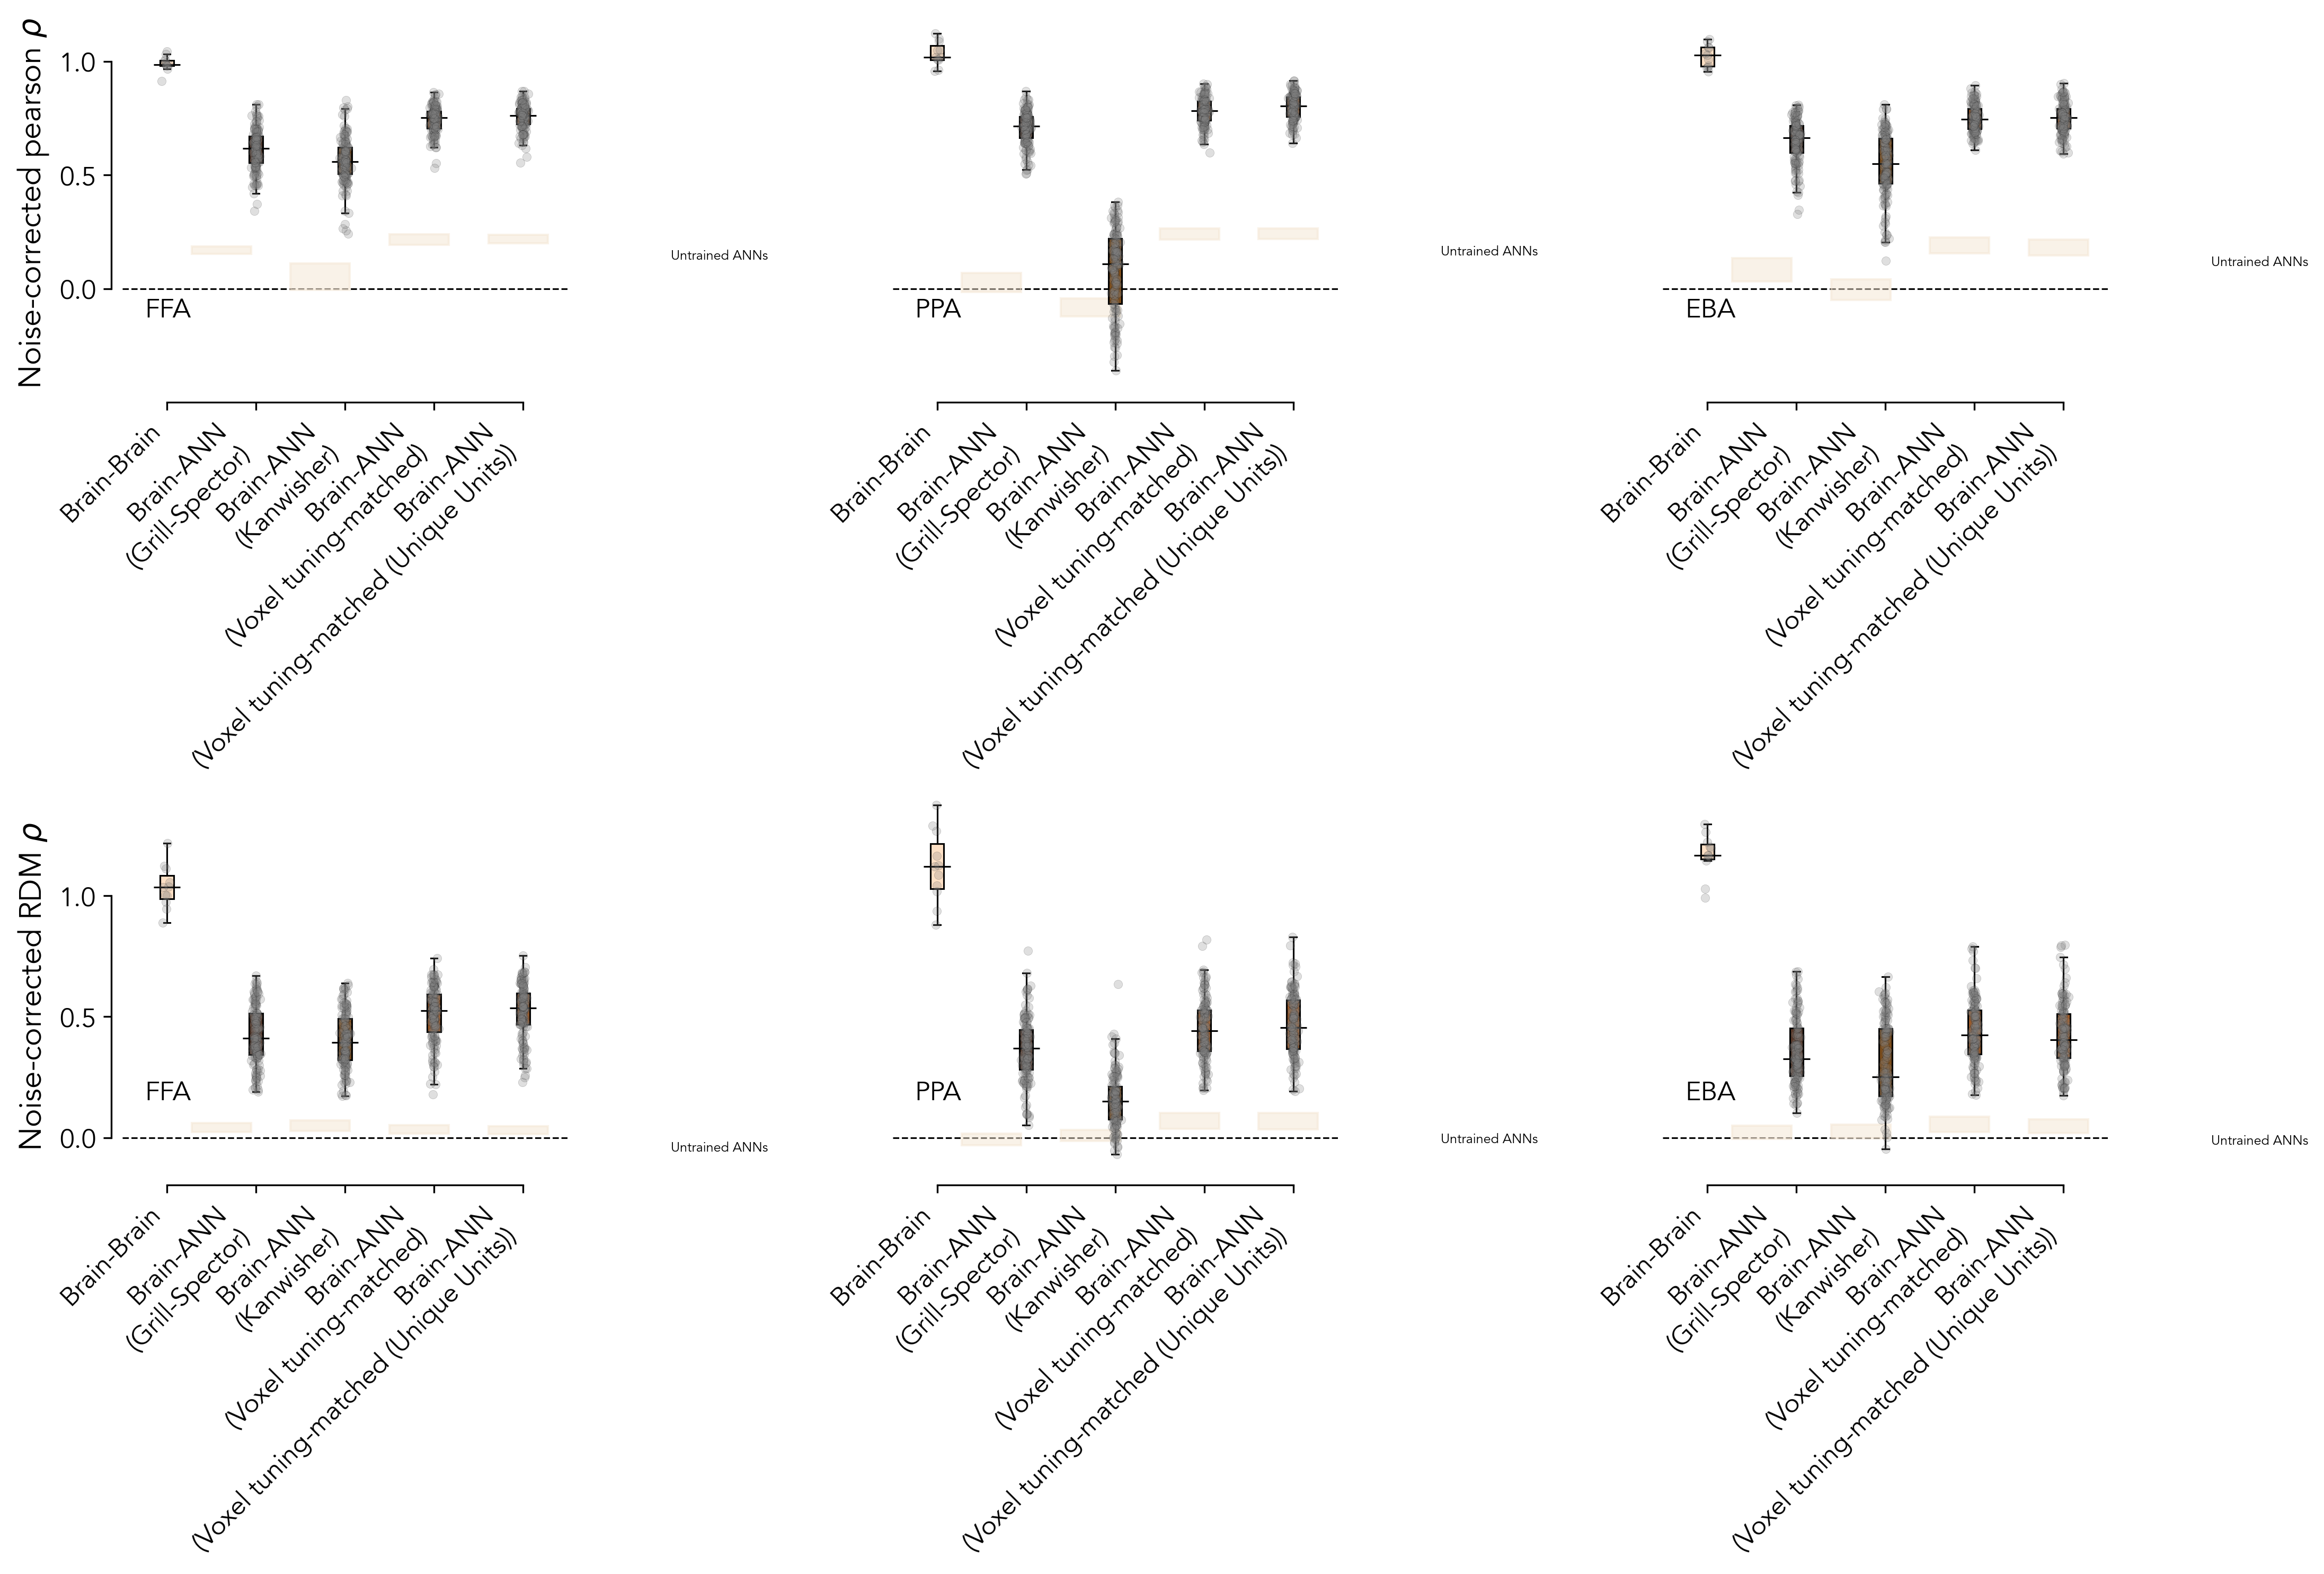

In [ ]:
tthreshold = 7
randommodel_tthreshold = 3
frois = ['FFA', 'PPA', 'EBA']
model_localizers = ['grillspector', 'kanwisher', 'nsd', 'nsd_uniqueunitpervoxel']

SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'
MODELSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/modelsubject_correlations_nsd515.csv'

all_task_optimized_model_names = ma.get_model_names(model_type='task_optimized')
all_random_model_names = ma.get_model_names(model_type='random')

savefig = False

plot_dir = f'{PLOTS_DIR}/fig3/boxplots'
os.makedirs(plot_dir, exist_ok=True)

subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
modelsubject_correlations_csv = pd.read_csv(MODELSUBJECT_CORRELATIONS_CSV_PATH)

# frois = subjectsubject_correlations_csv['fmri_froi'].unique()
subjects = subjectsubject_correlations_csv['subject1'].unique()
# subjects = [1, 2, 5, 7]
# subjects = [3, 4, 6, 8]
models = modelsubject_correlations_csv['model_name'].unique()

taskoptimized_models = [model for model in models if model in all_task_optimized_model_names]
# Random models
random_models = [model for model in models if model in all_random_model_names]

hh_color = '#fde0c5' # Light peach
random_color = '#f5e6d3' # Very light brown

localizer_color_dict = {
    'grillspector': '#5c3a29',  # Dark Brown
    'kanwisher': '#7f4e1a',     # A Shade lighter than dark brown
    'nsd': '#a65f2a',            # A shade lighter than that
    'nsd_uniqueunitpervoxel': '#a65f2a'            # A shade lighter than that
}
localizer_name_dict = {
    'grillspector': 'Grill-Spector',
    'kanwisher': 'Kanwisher',
    'nsd': 'Voxel tuning-matched',
    'nsd_uniqueunitpervoxel': 'Voxel tuning-matched (Unique Units)'
}

metrics = ['normed_pearsonr', 'normed_rdmr']
lims_dict = {
    'normed_pearsonr': (-0.45, 1.2),
    'normed_rdmr': (-0.15, 1.4)
}
ticks_dict = {
    'normed_pearsonr': [0, 0.5, 1],
    'normed_rdmr': [0, 0.5, 1]
}

# fig, ax = plt.figure(figsize=(5, 5), dpi=300)
fig, axes = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

for midx, metric in enumerate(metrics):
    print()
    print(metric)
    for fidx, froi in enumerate(frois):
        ax = axes[midx, fidx]
        print(froi)
        hh_medians = []
        for subject in subjects:
            subjectsubject_froi = subjectsubject_correlations_csv[
                (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                (subjectsubject_correlations_csv['subject1'] == subject) &
                (subjectsubject_correlations_csv['fmri_tthreshold'] == tthreshold)
            ]
            hh_medians += list(subjectsubject_froi[metric])
        hh_medians = np.array(hh_medians).flatten()
        print(f'Human median: {np.median(hh_medians)}')

        # Model correlations
        model_corrs = {}
        for model_localizer in model_localizers:
            model_corrs[model_localizer] = {}
            # Get random model correlations
            random_medians = []
            for model in random_models:
                modelsubject_froi = modelsubject_correlations_csv[
                    (modelsubject_correlations_csv['fmri_froi'] == froi) &
                    (modelsubject_correlations_csv['model_name'] == model) &
                    (modelsubject_correlations_csv['fmri_tthreshold'] == randommodel_tthreshold) &
                    (modelsubject_correlations_csv['model_tthreshold'] == randommodel_tthreshold) &
                    (modelsubject_correlations_csv['model_localizer'] == model_localizer) &
                    (modelsubject_correlations_csv['subject'].isin(subjects))
                ]
                # Take median across subjects for this model
                random_medians += list(modelsubject_froi[metric])
            random_medians = np.array(random_medians)
            model_corrs[model_localizer]['random'] = random_medians

            # Separate task-optimized and brain-optimized models
            to_medians = []
            for model in taskoptimized_models:
                modelsubject_froi = modelsubject_correlations_csv[
                    (modelsubject_correlations_csv['fmri_froi'] == froi) &
                    (modelsubject_correlations_csv['model_name'] == model) &
                    (modelsubject_correlations_csv['fmri_tthreshold'] == tthreshold) &
                    (modelsubject_correlations_csv['model_tthreshold'] == tthreshold) &
                    (modelsubject_correlations_csv['model_localizer'] == model_localizer) &
                    (modelsubject_correlations_csv['subject'].isin(subjects))
                ]
                model_medians = list(modelsubject_froi[metric])
                if 'nsd' in model_localizer and midx == 1 and froi == 'FFA':
                    print(f'{model_localizer}; {model} median: {np.median(model_medians)}')
                # Mann-Whitney U test for each model vs. hh_medians
                ustat, pval = scipy.stats.mannwhitneyu(model_medians, hh_medians, alternative='less')
                if pval >= 0.05:
                    print(f"Model {model} ({model_localizer}) is plausibly within the human population (p={pval:.2e})")
                to_medians += model_medians
            model_corrs[model_localizer]['task_optimized'] = np.array(to_medians)

        jitter_scale = 0.01 #0.05
        scatter_pad = 0 # 0.05
        alpha = 0.25 # 0.5
        markersize = 15 # 25

        # bar_positions = np.array([0, 0.5, 1.0, 1.5, 2.0])
        bar_positions = np.arange(0, 0.5*(len(model_localizers)+1), 0.5)

        # y=0 line
        ax.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75, zorder=0)

        # Shaded region for random model correlations
        # if len(random_medians) > 0:
        #     random_q1 = np.percentile(random_medians, 25)
        #     random_q3 = np.percentile(random_medians, 75)
        #     ax.axhspan(random_q1, random_q3, color=random_color, alpha=0.5, zorder=1)
        #     # Add text annotation for Random Models
        #     random_median = np.median(random_medians)
        #     ax.text(0.35, random_median, 'Untrained ANNs', fontsize=10, va='center', ha='right', 
        #             transform=ax.get_yaxis_transform())
        for i, model_localizer in enumerate(model_localizers):
            i = i + 1  # Shift by 1 since 0 is hh
            random_medians = model_corrs[model_localizer]['random']
            random_q1 = np.percentile(random_medians, 25)
            random_q3 = np.percentile(random_medians, 75)
            # Keep shifting the shaded region to the right for each localizer
            ax.axhspan(random_q1, random_q3, color=random_color, alpha=0.5, zorder=1,
                       xmin=(bar_positions[i] - 0.15)/(bar_positions[-1]+0.25),
                       xmax=(bar_positions[i] + 0.15)/(bar_positions[-1]+0.25))
            if i == len(model_localizers) - 1:
                # Add text annotation for Random Models
                random_median = np.median(random_medians)
                ax.text(bar_positions[-2]-0.05, random_median-0.075, f'Untrained ANNs', fontsize=6, va='center', ha='right', 
                        transform=ax.get_yaxis_transform())

        # Box plot for brain-brain, and brain-ann for each model localizer
        box_data = [hh_medians]
        for model_localizer in model_localizers:
            box_data.append(model_corrs[model_localizer]['task_optimized'])
        linewidth = 0.75
        barwidth = 0.075 # 0.35
        medianlineextra = 0.075
        boxes = ax.boxplot(
                    box_data, positions=bar_positions, patch_artist=True, 
                    widths=barwidth, showfliers=False,
                    boxprops={'color': 'black', 'linewidth': linewidth},
                    whiskerprops=dict(linewidth=linewidth),
                    capprops=dict(linewidth=linewidth),
                    medianprops={'color': 'black', 'linewidth': linewidth},
                    flierprops=dict(marker='o', markersize=5, linewidth=linewidth)
                )
        for i, data in enumerate(box_data):
            med = np.median(data)
            # Manually draw a longer median line
            x = bar_positions[i]  # X-position of the boxplot
            # 0.225
            ax.plot([x - medianlineextra, x + medianlineextra], [med, med], color='black', linewidth=linewidth, solid_capstyle='butt')
        
        # Color the boxes according to category colors
        colors = [hh_color] + [localizer_color_dict[model_localizer] for model_localizer in model_localizers]
        for box, color in zip(boxes['boxes'], colors):
            box.set(facecolor=color)
        
        # Scatter individual data points
        for i, data in enumerate(box_data):
            x_ = np.zeros(len(data)) + bar_positions[i] + np.random.normal(0, jitter_scale, len(data))
            x_ += scatter_pad
            ax.scatter(
                x_, data, color='gray', alpha=alpha, zorder=5,
                edgecolors=(0, 0, 0), s=markersize, linewidths=0.15
            )
            # print(f'Bar position {bar_positions[i]}: n={len(data)}')
        
        # Write froi name in bottom left corner
        ax.text(0.05, 0.25, froi, transform=ax.transAxes, fontsize=12, verticalalignment='top')

        yticks = np.array(ticks_dict[metric])
        ylims = lims_dict[metric]
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.set_yticks(yticks)
        ax.set_yticklabels(yticks, fontsize=12)
        ax.spines['left'].set_bounds(yticks.min(), yticks.max())
        # plt.tick_params(axis='y', labelleft=False)
        ax.set_ylim(ylims)
        ax.spines['bottom'].set_bounds(bar_positions[0], bar_positions[-1])
        ax.set_xlim(bar_positions[0]-0.25, bar_positions[-1]+0.25)
        # ax.tick_params(axis='x', labelbottom=False)

        if fidx != 0:
            ax.spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            ax.yaxis.set_ticks([])
        else:
            if metric == 'normed_pearsonr':
                ax.set_ylabel(r'Noise-corrected pearson $\rho$', fontsize=14)
            else:
                ax.set_ylabel(r'Noise-corrected RDM $\rho$', fontsize=14)
        # x-label on all plots for now
        # ax.set_xticks(bar_positions, ['Brain-Brain', 'Brain-ANN\n(Task-Optimized)', 'Brain-ANN\n(Brain-Optimized)'], fontsize=12)
        xtick_labels = ['Brain-Brain'] + \
            [f'Brain-ANN\n({localizer_name_dict[model_localizer]})' for model_localizer in model_localizers]
        ax.set_xticks(bar_positions)
        ax.set_xticklabels(xtick_labels, fontsize=12, rotation=45, ha='right')

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/fig3_sup_otherfrois.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
# plt.savefig(f'{plot_dir}/modelhuman_univariate_{froi}.pdf')
plt.close()
